# Stage 3d: periodic boundary conditions, on α-quartz

So far every structure has been a finite object: the SiO₄ cluster, ethanol. Your SiO₂ work is about **crystals and glasses**, which are effectively infinite. Simulations handle that with **periodic boundary conditions (PBC)**: you model one box of atoms, the **unit cell**, and pretend it repeats forever in every direction.

The good news: NequIP doesn't change at all. The only new ingredient is how edges are built. The less obvious news: two of the symmetry checks you've learned behave differently in a crystal, and one quantity (net torque) stops making sense.

What we cover, in order:
1. The picture: one cell, infinitely many copies
2. Neighbours: what goes wrong without PBC
3. The one-line change inside the model
4. The symmetry table, crystal edition
5. The torque puzzle
6. Stress: how the energy responds to stretching the box
7. Why bother: a crystal vs a chunk cut out of it
8. Aside: left- vs right-handed quartz

Everything here uses an **untrained** NequIP (random weights) in float64. That's on purpose: as in the last quiz, the symmetry and conservation properties hold for **any** weights, so we don't need a trained SiO₂ model to check them. The energies themselves are meaningless numbers, in arbitrary "model units".

In [1]:
import warnings
warnings.filterwarnings("ignore")
import inspect
import numpy as np
import torch
import matplotlib.pyplot as plt
from ase import Atoms
from ase.spacegroup import crystal
from ase.neighborlist import neighbor_list

from nequip.utils.global_state import set_global_state
set_global_state()
from nequip.model import NequIPGNNModel
from nequip.integrations.ase import NequIPCalculator
from nequip.data.transforms import ChemicalSpeciesToAtomTypeMapper, NeighborListTransform
import nequip.nn.utils

# ---- palette (same style as the other stage-3 notebooks) ----
GOOD, CRITICAL, INK, MUTED, BAND, BG = "#0ca30c", "#d03b3b", "#0b0b0b", "#52514e", "#f0efec", "#fcfcfb"
BLUE, ORANGE, PURPLE = "#2a6fdb", "#e08a1e", "#7b4fc9"
plt.rcParams.update({"figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
                     "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 9,
                     "axes.titlesize": 10, "axes.titlelocation": "left", "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})
SI_COL, O_COL = "#e0a030", "#d03b3b"
COL = {"Si": SI_COL, "O": O_COL}
SIZE = {"Si": 160, "O": 90}

## 1. The picture: one cell, infinitely many copies

α-quartz, the stable form of SiO₂ at room temperature. Its unit cell is a slanted hexagonal box (a = b = 4.913 Å, c = 5.405 Å, 120° between a and b) holding **3 Si and 6 O**. Every Si sits in a tetrahedron of 4 O, and every O bridges 2 Si: the same SiO₄ unit as the e3nn notebook's cluster, now linked into an endless network.

(Structure: space group P3₂21, coordinates from Levien et al. 1980. ASE's setting for this space group puts the origin ⅔ of the way up c, hence the `+ 2/3` below.)

In [2]:
quartz = crystal(["Si", "O"], basis=[(0.4697, 0, 2/3), (0.4135, 0.2669, 0.1191 + 2/3)], spacegroup=154,
                 cellpar=[4.9134, 4.9134, 5.4052, 90, 90, 120])
sym = np.array(quartz.get_chemical_symbols())
i, j, D = neighbor_list("ijD", quartz, 2.0)
d = np.linalg.norm(D, axis=1)
o0 = np.where(sym == "O")[0][0]
v = D[i == o0]
angle = np.degrees(np.arccos(v[0] @ v[1] / np.linalg.norm(v[0]) / np.linalg.norm(v[1])))
print(quartz.get_chemical_formula(mode="hill"), "| atoms in the cell:", len(quartz), f"| volume {quartz.get_volume():.1f} Å³")
print("Si–O bond lengths:", np.unique(np.round(d, 3)), "Å   (experiment: 1.605, 1.614)")
print(f"Si–O–Si angle: {angle:.1f}°   (experiment: ~144°)")
print("neighbours within 2 Å: Si", [int((i == k).sum()) for k in np.where(sym == "Si")[0]],
      "| O", [int((i == k).sum()) for k in np.where(sym == "O")[0]])

O6Si3 | atoms in the cell: 9 | volume 113.0 Å³
Si–O bond lengths: [1.604 1.613] Å   (experiment: 1.605, 1.614)
Si–O–Si angle: 143.7°   (experiment: ~144°)
neighbours within 2 Å: Si [4, 4, 4] | O [2, 2, 2, 2, 2, 2]


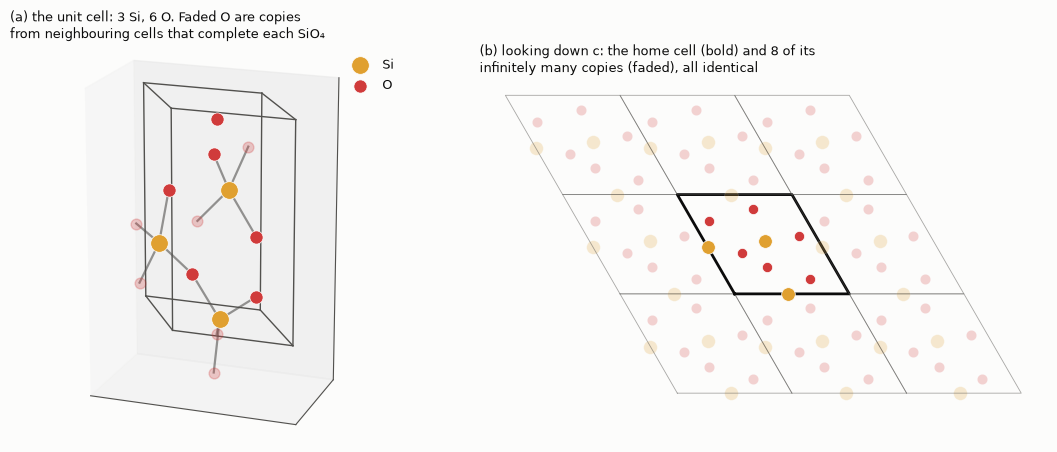

In [3]:
def cell_outline(ax, cell, shift=(0, 0), **kw):
    a1, a2 = cell[0, :2], cell[1, :2]
    s = np.array(shift[0] * a1 + shift[1] * a2)
    corners = np.array([[0, 0], a1, a1 + a2, a2, [0, 0]]) + s
    ax.plot(*corners.T, **kw)

def top_view(ax, atoms, tiles=1, title=""):
    # view down the c axis; faded copies are the periodic images
    cell = atoms.cell.array
    for n1 in range(-tiles, tiles + 1):
        for n2 in range(-tiles, tiles + 1):
            home = n1 == 0 and n2 == 0
            shift = n1 * cell[0] + n2 * cell[1]
            for s in ["O", "Si"]:
                p = atoms.positions[sym == s] + shift
                ax.scatter(p[:, 0], p[:, 1], s=SIZE[s] * 0.6, color=COL[s], alpha=1 if home else 0.22,
                           edgecolor="white", linewidth=0.5, zorder=3 if home else 2)
            cell_outline(ax, cell, (n1, n2), color=INK if home else MUTED, lw=2 if home else 0.6, alpha=1 if home else 0.5)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_title(title, loc="left", fontsize=9.5)

fig = plt.figure(figsize=(11.5, 4.6))
ax = fig.add_subplot(1, 2, 1, projection="3d")
cell = quartz.cell.array
for a, b in [(0, 1), (0, 2), (0, 4), (1, 3), (1, 5), (2, 3), (2, 6), (3, 7), (4, 5), (4, 6), (5, 7), (6, 7)]:
    corner = lambda k: (k & 1) * cell[0] + ((k >> 1) & 1) * cell[1] + ((k >> 2) & 1) * cell[2]
    ax.plot(*zip(corner(a), corner(b)), color=MUTED, lw=1)
for a_, b_, Dv in zip(i, j, D):
    if sym[a_] == "Si":
        ax.plot(*zip(quartz.positions[a_], quartz.positions[a_] + Dv), color=MUTED, lw=1.6, alpha=0.6)
        ax.scatter(*(quartz.positions[a_] + Dv), s=60, color=O_COL, alpha=0.25, depthshade=False)
for s in ["Si", "O"]:
    p = quartz.positions[sym == s]
    ax.scatter(*p.T, s=SIZE[s], color=COL[s], depthshade=False, edgecolor="white", linewidth=0.5, label=s)
ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([]); ax.view_init(18, -70)
ax.set_box_aspect(np.ptp(np.vstack([cell.sum(0), np.zeros(3), cell[0], cell[1]]), axis=0) + [0, 0, 5.4])
ax.set_title("(a) the unit cell: 3 Si, 6 O. Faded O are copies\nfrom neighbouring cells that complete each SiO₄", loc="left", fontsize=9.5)
ax.legend(frameon=False, loc="upper right")
top_view(fig.add_subplot(1, 2, 2), quartz, tiles=1,
         title="(b) looking down c: the home cell (bold) and 8 of its\ninfinitely many copies (faded), all identical")
plt.tight_layout(); plt.show()

**The picture to keep:** the simulation only stores the 9 atoms in the bold cell. Every faded atom is a **periodic image**: an exact copy, shifted by a whole number of cell vectors. When an atom in the home cell moves, all of its copies move in lockstep.

Notice in (a) that most SiO₄ tetrahedra **cross the cell boundary**. Half of each Si's oxygens "live" in a neighbouring cell. That's normal: where you draw the box is an arbitrary bookkeeping choice, and the crystal doesn't care.

## 2. Neighbours: what goes wrong without PBC

Let's count each atom's bonds (neighbours within 2 Å) twice: once treating the 9 atoms as an isolated cluster, and once with PBC switched on.

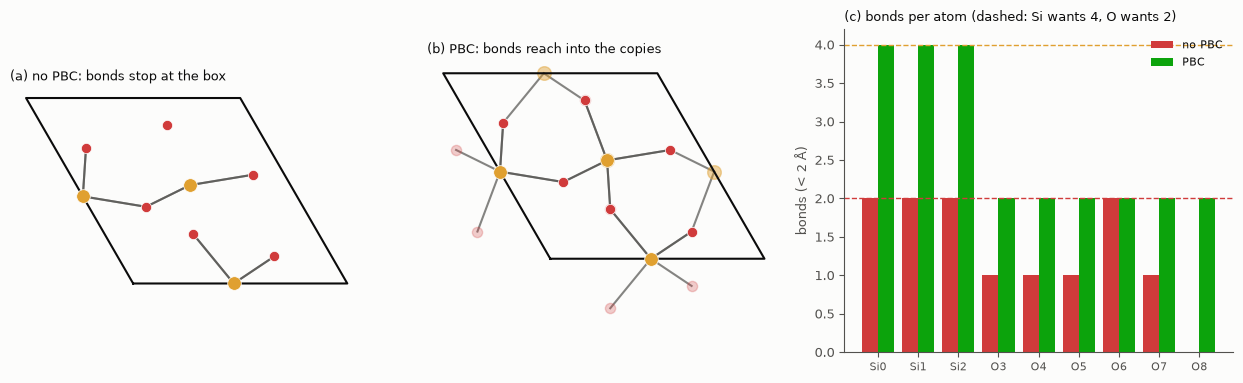

no PBC: Si bonds [2 2 2] O bonds [1 1 1 2 1 0]
PBC:    Si bonds [4 4 4] O bonds [2 2 2 2 2 2]


In [4]:
cluster = quartz.copy(); cluster.set_pbc(False)
cn_pbc = np.bincount(neighbor_list("i", quartz, 2.0), minlength=len(quartz))
cn_free = np.bincount(neighbor_list("i", cluster, 2.0), minlength=len(quartz))

fig, axs = plt.subplots(1, 3, figsize=(12.5, 3.9), gridspec_kw={"width_ratios": [1, 1, 1.1]})
for ax, atoms, pbc, title in [(axs[0], cluster, False, "(a) no PBC: bonds stop at the box"),
                              (axs[1], quartz, True, "(b) PBC: bonds reach into the copies")]:
    ii, jj, DD = neighbor_list("ijD", atoms, 2.0)
    for a_, Dv in zip(ii, DD):
        p0 = atoms.positions[a_][:2]
        ax.plot(*zip(p0, p0 + Dv[:2]), color=MUTED, lw=1.5, alpha=0.7, zorder=1)
    if pbc:   # draw the image atoms that the bonds land on
        for a_, b_, Dv in zip(ii, jj, DD):
            q = atoms.positions[a_] + Dv
            if not np.allclose(q, atoms.positions[b_]):
                ax.scatter(*q[:2], s=SIZE[sym[b_]] * 0.6, color=COL[sym[b_]], alpha=0.25, zorder=2)
    for s in ["O", "Si"]:
        p = atoms.positions[sym == s]
        ax.scatter(p[:, 0], p[:, 1], s=SIZE[s] * 0.6, color=COL[s], edgecolor="white", linewidth=0.5, zorder=3)
    cell_outline(ax, quartz.cell.array, color=INK, lw=1.5)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, loc="left", fontsize=9.5)
    for sp in ax.spines.values():
        sp.set_visible(False)
x = np.arange(len(quartz))
axs[2].bar(x - 0.2, cn_free, 0.4, color=CRITICAL, label="no PBC")
axs[2].bar(x + 0.2, cn_pbc, 0.4, color=GOOD, label="PBC")
axs[2].set_xticks(x, [f"{s}{k}" for k, s in enumerate(sym)], fontsize=8)
axs[2].axhline(4, color=SI_COL, ls="--", lw=1); axs[2].axhline(2, color=O_COL, ls="--", lw=1)
axs[2].set_ylabel("bonds (< 2 Å)"); axs[2].set_title("(c) bonds per atom (dashed: Si wants 4, O wants 2)", loc="left", fontsize=9.5)
axs[2].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
print("no PBC: Si bonds", cn_free[sym == "Si"], "O bonds", cn_free[sym == "O"])
print("PBC:    Si bonds", cn_pbc[sym == "Si"], "O bonds", cn_pbc[sym == "O"])

Without PBC, most atoms are missing bonds: the model would see a small cluster riddled with **dangling bonds**, i.e. a surface, not bulk quartz. With PBC every Si has its 4 O and every O its 2 Si, exactly as in the infinite crystal.

## 3. The one-line change inside the model

Recall from the walkthrough: NequIP never looks at positions directly. Every layer only sees **edge vectors** (where neighbour j is relative to atom i). For a molecule:

  edge vector = pos[j] − pos[i]

With PBC, neighbour j may be a *copy* of atom j, sitting a whole number of cells away. The neighbour list records which copy as three integers, the **cell shift** S (for example (1, 0, 0) = "one cell along a"). The edge vector becomes:

  edge vector = pos[j] − pos[i] + S · cell

That's the entire change. Here it is in nequip's source:

In [5]:
src = inspect.getsource(nequip.nn.utils.with_edge_vectors_).splitlines()
start = next(k for k, line in enumerate(src) if "edge_vec = torch.index_select(pos" in line)
print("\n".join(src[start:start + 3]))
print("        ...")
stop = next(k for k, line in enumerate(src) if "edge_cell_shift.view(-1, 3, 1) * cell.view(3, 3)" in line)
print("\n".join(src[stop - 1:stop + 2]))

        edge_vec = torch.index_select(pos, 0, edge_index[1]) - torch.index_select(
            pos, 0, edge_index[0]
        )
        ...
                edge_vec = edge_vec + torch.sum(
                    edge_cell_shift.view(-1, 3, 1) * cell.view(3, 3), 1
                )


Everything after this line (spherical harmonics of the edge direction, Bessel functions of its length, tensor products, the energy sum) is **identical** to the ethanol model. The model can't even tell whether a neighbour is an image or not.

### A surprise: atoms that neighbour themselves

The trained ethanol model used a 4 Å cutoff. Bulk models typically use 5 Å or more. But quartz's cell is only 4.91 Å along a and b, so with a 5 Å cutoff each atom is within range of **six copies of itself** (one cell away along ±a, ±b and ±(a+b)), and of several copies of every other atom. Let's look at every edge of one Si atom.

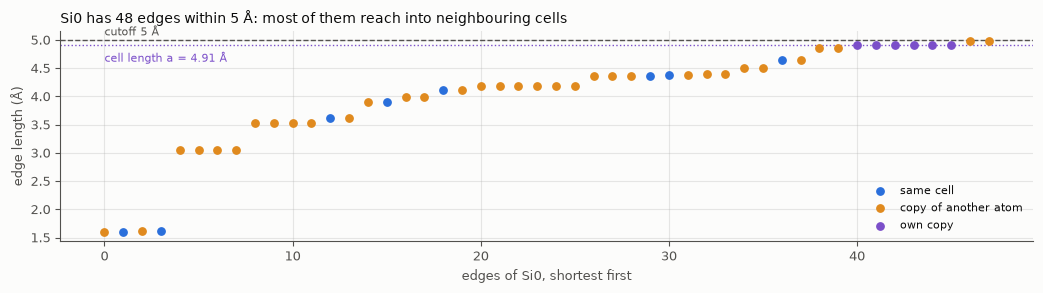

whole cell: 408 edges, 54 of them to an atom's own copy
distinct (i, j) atom pairs: 72. A 'one copy per pair' neighbour list would keep only 72 edges
and silently drop 336.


In [6]:
R_MAX = 5.0
ii, jj, SS, dd = neighbor_list("ijSd", quartz, R_MAX)
k = 0                                                  # the first Si
mask = ii == k
kind = np.where(jj[mask] == k, "own copy", np.where(np.any(SS[mask] != 0, axis=1), "copy of another atom", "same cell"))
order = np.argsort(dd[mask])

fig, ax = plt.subplots(figsize=(10.5, 3.0))
for lab, col in [("same cell", BLUE), ("copy of another atom", ORANGE), ("own copy", PURPLE)]:
    sel = kind[order] == lab
    ax.scatter(np.arange(mask.sum())[sel], dd[mask][order][sel], color=col, s=28, label=lab, zorder=3)
ax.axhline(R_MAX, color=MUTED, ls="--", lw=1); ax.text(0, R_MAX + 0.08, "cutoff 5 Å", color=MUTED, fontsize=8)
ax.axhline(quartz.cell.lengths()[0], color=PURPLE, ls=":", lw=1)
ax.text(0, quartz.cell.lengths()[0] - 0.3, "cell length a = 4.91 Å", color=PURPLE, fontsize=8)
ax.set_xlabel("edges of Si0, shortest first"); ax.set_ylabel("edge length (Å)")
ax.set_title(f"Si0 has {mask.sum()} edges within 5 Å: most of them reach into neighbouring cells", loc="left")
ax.legend(frameon=False, fontsize=8, loc="lower right"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

n_pairs = len({(a, b) for a, b in zip(ii, jj) if a != b})
print(f"whole cell: {len(ii)} edges, {int((ii == jj).sum())} of them to an atom's own copy")
print(f"distinct (i, j) atom pairs: {n_pairs}. A 'one copy per pair' neighbour list would keep only {n_pairs} edges")
print(f"and silently drop {len(ii) - n_pairs}.")

**Why this matters.** Older simulation codes often use the **minimum-image convention**: for each pair of atoms, keep only the *closest* copy. That's fine when the cutoff is less than half the cell size, but here it would throw away most of the edges and the model would see a different structure than the real crystal. Proper neighbour lists (ASE, matscipy, vesin; nequip uses matscipy by default) keep **every** copy within the cutoff. An atom seeing its own image is perfectly fine: it's just another neighbour that happens to move in lockstep with it.

## 4. The symmetry table, crystal edition

Now a NequIP model with random weights, a 5 Å cutoff and float64. One precaution first: perfect quartz has symmetries of its own (3-fold screw axes, 2-fold axes), and those can force some numbers to zero whatever the model does, which would make a check pass for the wrong reason. So from here on we test on a **jiggled** copy: every atom nudged by a few hundredths of an ångström and the box distorted by about 1%. It's still a periodic crystal, just a generic one.

Then the checks, each paired with the symmetry it tests. There are three new rows a molecule doesn't have: **periodicity** (which copy you call "the atom" doesn't matter), **rotating atoms but not the box** (not a symmetry), and **extensivity** (a bigger repeat of the same crystal has proportionally more energy).

In [7]:
def make_model(seed=0):
    return NequIPGNNModel(seed=seed, model_dtype="float64", r_max=R_MAX, type_names=["Si", "O"],
                          num_layers=3, l_max=1, num_features=16, radial_mlp_width=32,
                          avg_num_neighbors=float(len(ii)) / len(quartz),
                          per_type_energy_scales=1.0, per_type_energy_shifts=0.0).eval()

model = make_model()
calc = NequIPCalculator(model, device="cpu", transforms=[
    ChemicalSpeciesToAtomTypeMapper(model_type_names=["Si", "O"], chemical_species_to_atom_type_map={"Si": "Si", "O": "O"}),
    NeighborListTransform(r_max=R_MAX)])

def evaluate(atoms):
    a = atoms.copy(); a.calc = calc
    return a.get_potential_energy(), a.get_forces(), a.get_stress(voigt=False)

rng = np.random.default_rng(0)
base = quartz.copy()
base.set_cell(quartz.cell.array @ (np.eye(3) + 0.01 * rng.normal(size=(3, 3))), scale_atoms=True)
base.positions += 0.03 * rng.normal(size=base.positions.shape)
E0, F0, S0 = evaluate(base)
print(f"energy {E0:.4f} model units | largest force {np.abs(F0).max():.3f} | stress diagonal {np.diag(S0).round(4)}")

energy 0.0678 model units | largest force 0.033 | stress diagonal [-0.0009 -0.0011  0.0004]


In [8]:
cell0 = base.cell.array
Q, _ = np.linalg.qr(np.random.default_rng(1).normal(size=(3, 3)))
Rm = Q * np.sign(np.linalg.det(Q))                          # a proper rotation

def variant(pos=None, cell=None):
    a = base.copy()
    if cell is not None: a.set_cell(cell, scale_atoms=False)
    if pos is not None: a.positions = pos
    return a

p0 = base.positions
wrapped = p0.copy(); wrapped[0] += cell0[0] + cell0[1] - cell0[2]      # Si0 swapped for one of its copies
E_w, F_w, _ = evaluate(variant(pos=wrapped))
E_t, F_t, _ = evaluate(variant(pos=p0 + np.array([0.37, -1.21, 2.05])))
E_r, F_r, S_r = evaluate(variant(pos=p0 @ Rm.T, cell=cell0 @ Rm.T))      # atoms AND box rotated
E_a, F_a, _ = evaluate(variant(pos=p0 @ Rm.T))                          # atoms rotated, box not
big = base.repeat((2, 2, 2))
E_b, F_b, _ = evaluate(big)

rows = [("periodicity", "swap an atom for its copy: energy", abs(E_w - E0)),
        ("periodicity", "                       forces", np.abs(F_w - F0).max()),
        ("translation", "energy unchanged", abs(E_t - E0)),
        ("translation", "ΣF = 0", np.abs(F0.sum(0)).max()),
        ("rotation", "atoms + box: energy unchanged", abs(E_r - E0)),
        ("rotation", "atoms + box: forces turn along", np.abs(F_r - F0 @ Rm.T).max()),
        ("rotation", "atoms + box: stress turns along", np.abs(S_r - Rm @ S0 @ Rm.T).max()),
        ("extensivity", "2×2×2 copy: energy = 8 × energy", abs(E_b - 8 * E0)),
        ("extensivity", "2×2×2 copy: same forces", np.abs(F_b[:len(base)] - F0).max()),
        ("NOT a symmetry", "atoms rotated, box not: energy", abs(E_a - E0))]
print(f"float64 eps {np.finfo(float).eps:.1e} × energy scale {abs(E0):.1f} → round-off ≈ {np.finfo(float).eps * abs(E0):.0e} and up\n")
for s, prop, e in rows:
    flag = "   <- a real difference" if e > 1e-8 else ""
    print(f"{s:15s} {prop:36s} {e:.1e}{flag}")

float64 eps 2.2e-16 × energy scale 0.1 → round-off ≈ 2e-17 and up

periodicity     swap an atom for its copy: energy    8.3e-17
periodicity                            forces        2.6e-16
translation     energy unchanged                     1.4e-16
translation     ΣF = 0                               2.4e-17
rotation        atoms + box: energy unchanged        6.9e-17
rotation        atoms + box: forces turn along       4.3e-16
rotation        atoms + box: stress turns along      6.5e-17
extensivity     2×2×2 copy: energy = 8 × energy      0.0e+00
extensivity     2×2×2 copy: same forces              2.9e-16
NOT a symmetry  atoms rotated, box not: energy       2.4e-02   <- a real difference


**Reading the table.** Every row is at float64 round-off (around 1e-15), except the last one, where the energy genuinely changes.

- **Periodicity:** moving an atom by a whole cell vector just swaps it for one of its copies. The crystal is literally the same, so energy and forces can't change.
- **Translation → ΣF = 0, still.** Shifting every atom by the same amount doesn't change any edge vector, so the energy can't change, and the forces must sum to zero. Same argument as for ethanol.
- **Rotation needs the box to come along.** Rotating the atoms *and* the cell is a true symmetry. Rotating the atoms alone isn't. Picture the faded copies in §1: they stay where the old box puts them, so the rotated atoms near the boundary now clash with unrotated copies. That's a different, strained structure.
- **Extensivity:** a 2×2×2 block of the same crystal has 8× the energy and identical forces on every atom. That only works because each atom's environment is built from all copies within the cutoff, which is why the neighbour list from §3 must keep them all.

## 5. The torque puzzle

For ethanol, rotation symmetry gave **zero net torque**, Σ r × F = 0. Let's check that in quartz.

net torque, original box:       [-0.0469 -0.0428  0.0189]
net torque, Si0 swapped for copy: [ 0.0124 -0.1387 -0.0295]

same crystal, same forces (difference 3e-16), yet the torque changed by 0.10


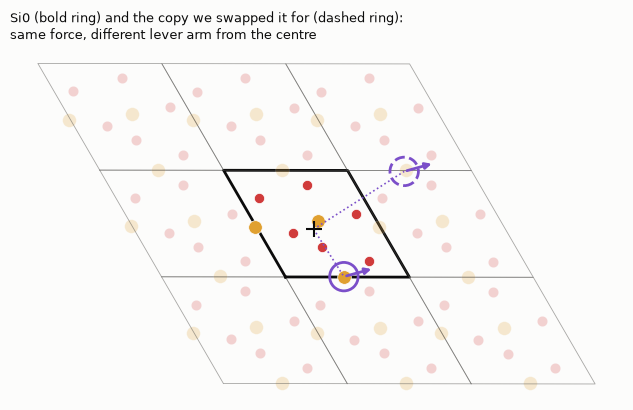

In [9]:
def torque(pos, F):
    return np.cross(pos - pos.mean(0), F).sum(0)

T0 = torque(p0, F0)
T_w = torque(wrapped, F_w)
print("net torque, original box:      ", T0.round(4))
print("net torque, Si0 swapped for copy:", T_w.round(4))
print(f"\nsame crystal, same forces (difference {np.abs(F_w - F0).max():.0e}), yet the torque changed by {np.abs(T_w - T0).max():.2f}")

fig, ax = plt.subplots(figsize=(6.4, 4.6))
top_view(ax, base, tiles=1, title="Si0 (bold ring) and the copy we swapped it for (dashed ring):\nsame force, different lever arm from the centre")
c = p0.mean(0)[:2]
scale = 1.2 / np.abs(F0[0, :2]).max()
for p, ls in [(p0[0], "-"), (wrapped[0], "--")]:
    ax.scatter(*p[:2], s=420, facecolor="none", edgecolor=PURPLE, lw=2, ls=ls, zorder=5)
    ax.plot(*zip(c, p[:2]), color=PURPLE, lw=1.2, ls=":", zorder=4)
    ax.annotate("", xy=p[:2] + scale * F0[0, :2], xytext=p[:2],
                arrowprops=dict(arrowstyle="-|>", color=PURPLE, lw=2), zorder=6)
ax.scatter(*c, marker="+", s=120, color=INK, zorder=6)
plt.tight_layout(); plt.show()

**What's going on.** Net torque isn't zero, and worse, it isn't even well-defined: it depends on which copy of each atom you happen to store. Swapping Si0 for its copy (the same crystal, with the same forces) changes its lever arm, so the "net torque" changes too. In a crystal, **Σ r × F is not a physical quantity**, so it can't be a symmetry check.

Where did the rotation law go? Into the box. In a crystal, rotating the atoms and the box together is the symmetry, and its conservation law shows up as a property of the **stress**, next section.

## 6. Stress: how the energy responds to stretching the box

Forces answer "how does the energy change if I move one atom?". **Stress** answers "how does the energy change if I deform the whole box?": stretch it along z, shear it in the xy plane, and so on. Formally, stress = (1/volume) × dE/d(strain). It's what tells you the pressure in a simulation and lets a cell relax to its natural shape. For your SiO₂ work it's essential: density and elastic constants come from it.

nequip computes stress the same way it computes forces, by autograd, by sneaking a strain into the cell and positions and differentiating with respect to it. Let's check it against an explicit finite difference: actually stretch the box a little, recompute the energy, and measure the slope.

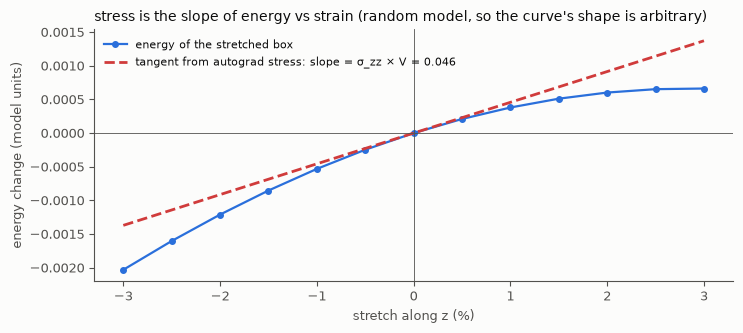

autograd stress vs finite difference, largest difference: 2.3e-12
symmetry of the stress, from the un-symmetrised finite differences:
   σ[0,1] = +1.009e-04   σ[1,0] = +1.009e-04   difference 4e-14
   σ[0,2] = -1.870e-04   σ[2,0] = -1.870e-04   difference 2e-13
   σ[1,2] = -1.295e-04   σ[2,1] = -1.295e-04   difference 6e-14


In [10]:
V = base.get_volume()

def strained(eps_matrix):
    a = base.copy(); a.set_cell(cell0 @ (np.eye(3) + eps_matrix), scale_atoms=True)
    return a

def energy(atoms):
    return evaluate(atoms)[0]

h = 1e-5
S_fd = np.zeros((3, 3))
for a_ in range(3):
    for b_ in range(3):
        e = np.zeros((3, 3)); e[a_, b_] = h          # deliberately NOT symmetrised: one off-diagonal entry at a time
        S_fd[a_, b_] = (energy(strained(e)) - energy(strained(-e))) / (2 * h) / V

strains = np.linspace(-0.03, 0.03, 13)
E_curve = [energy(strained(np.diag([0, 0, s]))) for s in strains]

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(100 * strains, np.array(E_curve) - E0, "o-", color=BLUE, lw=1.6, ms=4, label="energy of the stretched box")
ax.plot(100 * strains, S0[2, 2] * V * strains, color=CRITICAL, lw=2, ls="--",
        label=f"tangent from autograd stress: slope = σ_zz × V = {S0[2, 2] * V:.3f}")
ax.axhline(0, color=MUTED, lw=0.6); ax.axvline(0, color=MUTED, lw=0.6)
ax.set_xlabel("stretch along z (%)"); ax.set_ylabel("energy change (model units)")
ax.set_title("stress is the slope of energy vs strain (random model, so the curve's shape is arbitrary)")
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

print("autograd stress vs finite difference, largest difference:", f"{np.abs(S_fd - S0).max():.1e}")
print(f"symmetry of the stress, from the un-symmetrised finite differences:")
for a_, b_ in [(0, 1), (0, 2), (1, 2)]:
    print(f"   σ[{a_},{b_}] = {S_fd[a_, b_]:+.3e}   σ[{b_},{a_}] = {S_fd[b_, a_]:+.3e}   difference {abs(S_fd[a_, b_] - S_fd[b_, a_]):.0e}")

Two things to take from this:
- **Autograd stress matches the finite difference** to about 1e-12, which is the finite-difference error for a step of 1e-5. The red tangent touches the blue curve at zero strain.
- **The stress tensor is symmetric**: σ[x,y] = σ[y,x], and so on. This is where rotation symmetry went. A non-symmetric strain (shearing x by y but not y by x) is a symmetric strain plus a tiny **rotation** of the box. Rotating atoms and box together costs no energy, so only the symmetric part can matter. So in a crystal, **rotation symmetry ↔ symmetric stress**, playing the role that zero net torque played for a molecule.

| Symmetry | Molecule (ethanol) | Crystal (quartz) |
|---|---|---|
| Translation | ΣF = 0 | ΣF = 0 (unchanged) |
| Rotation | net torque Σ r × F = 0 | stress tensor is symmetric (torque isn't defined) |
| Periodicity | none | swapping an atom for its copy changes nothing |

## 7. Why bother: a crystal vs a chunk cut out of it

You might ask: why not just simulate a big enough cluster? This plot shows why. We cut chunks of n × n × n unit cells out of quartz, with free surfaces, and compare their energy per atom with the periodic crystal.

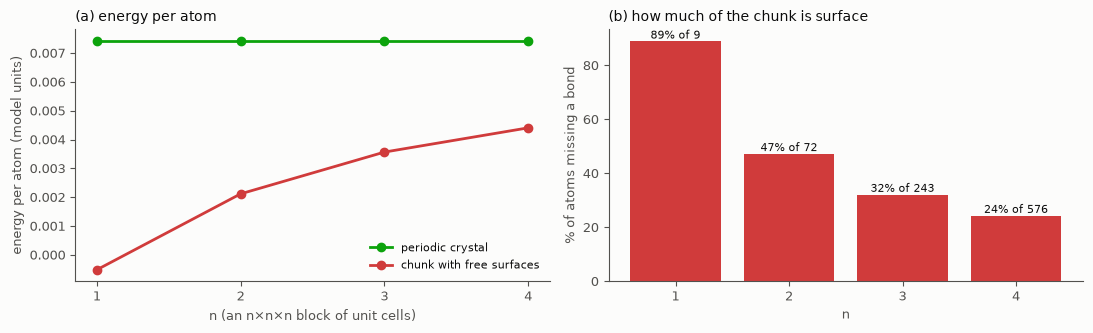

periodic energy per atom: [0.00742437 0.00742437 0.00742437 0.00742437]


In [11]:
ns = [1, 2, 3, 4]
e_chunk, e_bulk, frac_under = [], [], []
for n in ns:
    big = quartz.repeat((n, n, n))
    e_bulk.append(energy(big) / len(big))
    chunk = big.copy(); chunk.set_pbc(False)
    e_chunk.append(energy(chunk) / len(chunk))
    cn = np.bincount(neighbor_list("i", chunk, 2.0), minlength=len(chunk))
    want = np.where(np.array(chunk.get_chemical_symbols()) == "Si", 4, 2)
    frac_under.append((cn < want).mean())

fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
axs[0].plot(ns, e_bulk, "o-", color=GOOD, lw=2, label="periodic crystal")
axs[0].plot(ns, e_chunk, "o-", color=CRITICAL, lw=2, label="chunk with free surfaces")
axs[0].set_xlabel("n (an n×n×n block of unit cells)"); axs[0].set_ylabel("energy per atom (model units)")
axs[0].set_xticks(ns); axs[0].set_title("(a) energy per atom"); axs[0].legend(frameon=False, fontsize=8)
axs[1].bar(ns, 100 * np.array(frac_under), color=CRITICAL)
for n, f, N in zip(ns, frac_under, [9 * n**3 for n in ns]):
    axs[1].text(n, 100 * f + 1, f"{100 * f:.0f}% of {N}", ha="center", fontsize=8)
axs[1].set_xlabel("n"); axs[1].set_ylabel("% of atoms missing a bond"); axs[1].set_xticks(ns)
axs[1].set_title("(b) how much of the chunk is surface")
plt.tight_layout(); plt.show()
print("periodic energy per atom:", np.round(e_bulk, 10))

The periodic crystal gives the **same** energy per atom whatever n is (extensivity again): one 9-atom cell already represents the infinite crystal. The chunk creeps toward it only slowly, because surface atoms are a fraction ~1/n of the total: even at 576 atoms, a large share of the atoms are still missing a bond. You'd need enormous clusters to approximate bulk, while PBC gets there with 9 atoms.

For amorphous SiO₂, the same idea applies with a bigger box: a few hundred atoms of glass in a periodic box, where the disorder is real but the surfaces are not.

## 8. Aside: left- and right-handed quartz

Quartz is **chiral**: its SiO₄ tetrahedra spiral around the c axis, and the mirror-image crystal spirals the other way (space group P3₁21 instead of P3₂21). Both occur in nature. The mirror image is a different crystal: you can't rotate one into the other. Does the model know the difference?

In [12]:
n = np.random.default_rng(2).normal(size=3); n /= np.linalg.norm(n)
mirror = np.eye(3) - 2 * np.outer(n, n)                 # reflection through a randomly tilted plane
left = variant(pos=p0 @ mirror, cell=cell0 @ mirror)
E_left, F_left, _ = evaluate(left)
print("(on the jiggled cell, so no accidental symmetry helps)")
print(f"right-handed energy {E0:.12f}")
print(f"left-handed  energy {E_left:.12f}   difference {abs(E_left - E0):.1e}")
print(f"forces are the mirror images: largest difference {np.abs(F_left - F0 @ mirror).max():.1e}")

(on the jiggled cell, so no accidental symmetry helps)
right-handed energy 0.067764926905
left-handed  energy 0.067764926905   difference 4.2e-17
forces are the mirror images: largest difference 3.6e-16


Identical energies, and mirror-image forces. That's correct physics: the two hands of quartz really do have exactly the same energy, and NequIP's energy is invariant under rotations **and** mirrors, so it can't tell them apart.

But some properties *do* differ between the hands, like the direction quartz rotates polarised light. Such a quantity flips sign under a mirror while staying unchanged under rotations. In e3nn's language that's a **pseudoscalar**, `0o` (l = 0, odd parity), not a `0e` scalar like energy. A model meant to predict it needs a `0o` output; reading out `0e` features, as the energy head does, would always give the same answer for both hands. This is the "chirality / `0o`" topic deferred in the handoff.

## 9. What changes when you train on periodic data

Nothing in the model. In the training config, three things change:
- **Data:** frames with a cell and `pbc = True`, usually in extended XYZ files read with nequip's `ASEDataModule` (`train_file_path`, `val_file_path`, …), instead of the sGDML ethanol datamodule.
- **Loss and metrics:** `EnergyForceStressLoss` / `EnergyForceStressMetrics` instead of the energy-force versions, if your DFT data includes stress (it should, for cell relaxations).
- **Cutoff:** 5–6 Å is typical for oxides. As §3 showed, that's larger than the quartz cell, which is fine with a proper neighbour list.

The real bottleneck is data: DFT energies, forces and stresses for SiO₂ structures. That's the next decision to make together.

## Quiz (letters are fine)

**1.** In the quartz table, ΣF came out at ~1e-16. Which symmetry guarantees that?
- A) Rotation
- B) Translation
- C) Periodicity
- D) Inversion

**2.** Net torque Σ r × F came out large for the crystal. Why isn't that a bug?
- A) The model is untrained
- B) Float64 round-off
- C) Which copy of each atom you store is arbitrary, so Σ r × F isn't even well-defined; and rotating atoms without the box isn't a symmetry anyway
- D) The cutoff is bigger than the cell

**3.** In a crystal, rotation symmetry shows up as:
- A) ΣF = 0
- B) A symmetric stress tensor
- C) Energy of a 2×2×2 block = 8 × the energy
- D) Zero net torque

**4.** A colleague's code keeps only the closest copy of each neighbour (minimum image), with a 5 Å cutoff on quartz. What happens?
- A) Nothing: closest copies are all that matter
- B) It drops real edges, since the cutoff is larger than half the cell (even larger than the cell), so the model sees the wrong structure
- C) It double-counts edges
- D) It only matters for stress